# Phase 3 — Génération des séquences étiquetées

Ce notebook génère trois classes de séquences :

- `nominal` : atome unique, aucune anomalie.
- `atom_loss` : l'atome disparaît à un instant `t_loss`.
- `aberration_drift` : les coefficients de Zernike croissent linéairement.

Chaque séquence contient `n_frames` images de fluorescence.
Les séquences sont sauvegardées dans `data/<classe>/`.

**Important** : les performances sur ces données synthétiques ne sont
pas une preuve de performance sur les données réelles d'ArQuS.


In [2]:
import sys, os, time
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from onn_arquS.config import (
    LAMBDA_399, TrapConfig, ImagingConfig, SimulationConfig
)
from onn_arquS.physics import sigma_thermal, sample_positions_gaussian
from onn_arquS.imaging import (
    airy_psf, aberrated_psf, render_intensity, add_scmos_noise
)

np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['figure.dpi'] = 100

cfg_trap = TrapConfig()
cfg_img = ImagingConfig()
cfg_sim = SimulationConfig()

pixel_object_m = cfg_img.pixel_size_m / cfg_img.magnification
print(f'Pixel objet : {pixel_object_m*1e9:.1f} nm')
print(f'Grille : {cfg_sim.grid_size} x {cfg_sim.grid_size}')
print(f'Champ objet : {cfg_sim.grid_size * pixel_object_m*1e6:.2f} um')

Pixel objet : 65.0 nm
Grille : 128 x 128
Champ objet : 8.32 um


## 1. PSF de référence

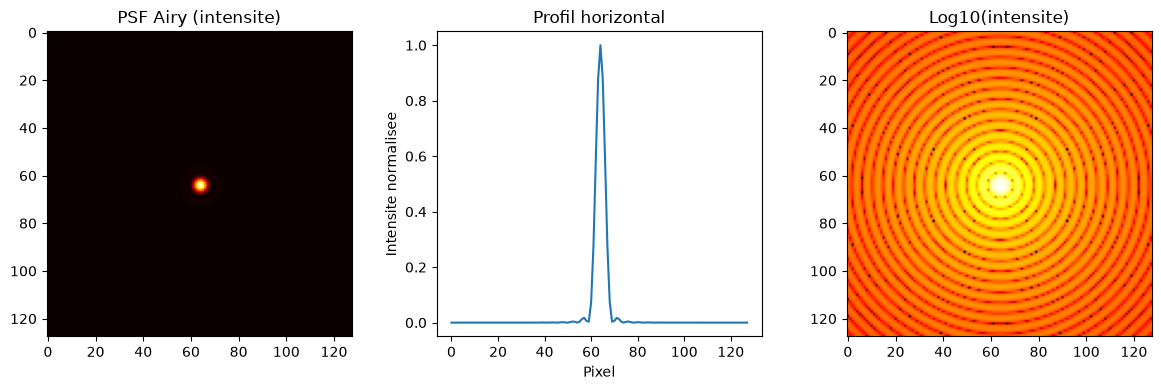

In [3]:
psf_ideal = airy_psf(cfg_sim.grid_size, pixel_object_m,
                      LAMBDA_399, cfg_img.numerical_aperture)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(psf_ideal, cmap='hot')
axes[0].set_title('PSF Airy (intensite)')
axes[1].plot(psf_ideal[cfg_sim.grid_size//2, :] / psf_ideal.max())
axes[1].set_xlabel('Pixel'); axes[1].set_ylabel('Intensite normalisee')
axes[1].set_title('Profil horizontal')
axes[2].imshow(np.log10(psf_ideal + 1e-30), cmap='hot')
axes[2].set_title('Log10(intensite)')
plt.tight_layout(); plt.show()

## 2. Fonctions de génération

In [4]:
def generate_nominal(n_frames, n_atoms=1, photons=1e4,
                     readout_std=2.0, background=10.0, rng=None):
    if rng is None:
        rng = np.random.default_rng(42)
    frames = []
    for _ in range(n_frames):
        positions = np.zeros((n_atoms, 2))
        for i in range(n_atoms):
            x = sample_positions_gaussian(cfg_trap.temperature_k,
                                          cfg_trap.omega_hz, 1, rng)[0]
            y = sample_positions_gaussian(cfg_trap.temperature_k,
                                          cfg_trap.omega_hz, 1, rng)[0]
            positions[i] = [x, y]
        img = render_intensity(positions, psf_ideal, pixel_object_m,
                               photons, background)
        img = add_scmos_noise(img, readout_std_map=np.full_like(img, readout_std),
                              gain_map=np.ones_like(img), rng=rng)
        frames.append(img)
    return np.array(frames), {'class': 'nominal', 'n_frames': n_frames,
                              'n_atoms': n_atoms}


def generate_atom_loss(n_frames, t_loss, n_atoms=1, photons=1e4,
                     readout_std=2.0, background=10.0, rng=None):
    if rng is None:
        rng = np.random.default_rng(42)
    frames = []
    for f in range(n_frames):
        if f >= t_loss:
            img = np.full((cfg_sim.grid_size, cfg_sim.grid_size), background)
            img = add_scmos_noise(img, readout_std_map=np.full_like(img, readout_std),
                                  gain_map=np.ones_like(img), rng=rng)
        else:
            positions = np.zeros((n_atoms, 2))
            for i in range(n_atoms):
                x = sample_positions_gaussian(cfg_trap.temperature_k,
                                              cfg_trap.omega_hz, 1, rng)[0]
                y = sample_positions_gaussian(cfg_trap.temperature_k,
                                              cfg_trap.omega_hz, 1, rng)[0]
                positions[i] = [x, y]
            img = render_intensity(positions, psf_ideal, pixel_object_m,
                                   photons, background)
            img = add_scmos_noise(img, readout_std_map=np.full_like(img, readout_std),
                                  gain_map=np.ones_like(img), rng=rng)
        frames.append(img)
    return np.array(frames), {'class': 'atom_loss', 'n_frames': n_frames,
                              't_loss': t_loss}


def generate_aberration_drift(n_frames, t_start, rate, n_atoms=1, photons=1e4,
                               readout_std=2.0, background=10.0, rng=None):
    if rng is None:
        rng = np.random.default_rng(42)
    frames = []
    for f in range(n_frames):
        coeff = (f - t_start) * rate if f >= t_start else 0.0
        psf_drift = aberrated_psf(cfg_sim.grid_size, pixel_object_m,
                                   LAMBDA_399, cfg_img.numerical_aperture,
                                   zernike_coeffs={(3, 1): coeff})
        positions = np.zeros((n_atoms, 2))
        for i in range(n_atoms):
            x = sample_positions_gaussian(cfg_trap.temperature_k,
                                          cfg_trap.omega_hz, 1, rng)[0]
            y = sample_positions_gaussian(cfg_trap.temperature_k,
                                          cfg_trap.omega_hz, 1, rng)[0]
            positions[i] = [x, y]
        img = render_intensity(positions, psf_drift, pixel_object_m,
                               photons, background)
        img = add_scmos_noise(img, readout_std_map=np.full_like(img, readout_std),
                              gain_map=np.ones_like(img), rng=rng)
        frames.append(img)
    return np.array(frames), {'class': 'aberration_drift', 'n_frames': n_frames,
                              't_start': t_start, 'rate': rate}

## 3. Visualisation : une séquence par classe

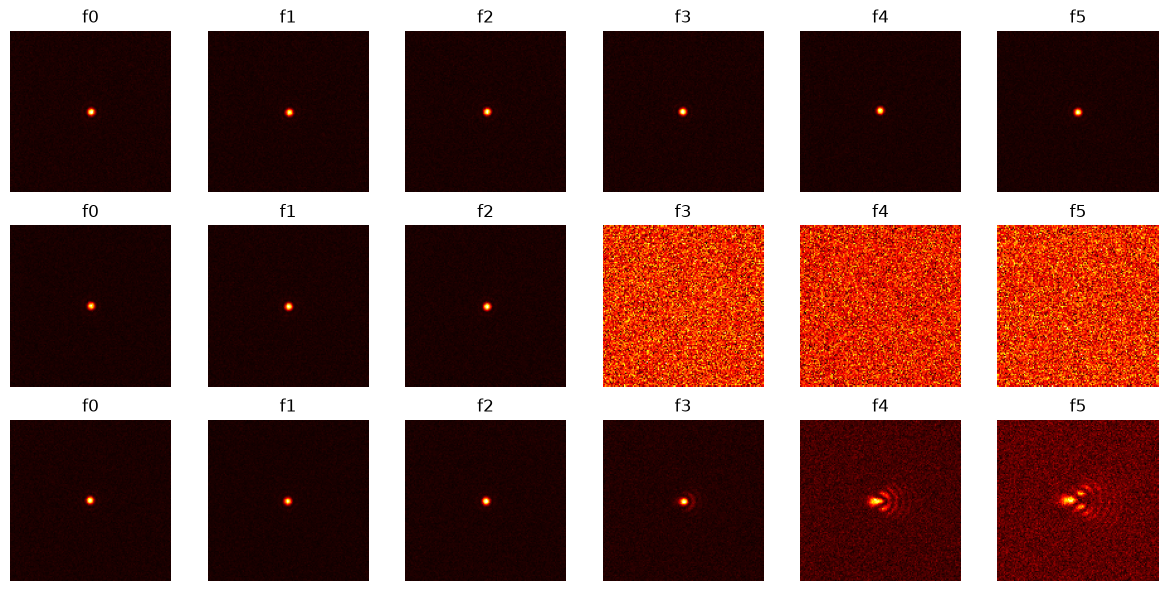

In [5]:
n_show = 6
rng = np.random.default_rng(0)

seq_nom, meta_nom = generate_nominal(n_show, rng=rng)
seq_loss, meta_loss = generate_atom_loss(n_show, t_loss=3, rng=rng)
seq_drift, meta_drift = generate_aberration_drift(n_show, t_start=2, rate=0.1, rng=rng)

fig, axes = plt.subplots(3, n_show, figsize=(2*n_show, 6))
for j in range(n_show):
    axes[0, j].imshow(seq_nom[j], cmap='hot'); axes[0, j].set_title(f'f{j}'); axes[0, j].axis('off')
    axes[1, j].imshow(seq_loss[j], cmap='hot'); axes[1, j].set_title(f'f{j}'); axes[1, j].axis('off')
    axes[2, j].imshow(seq_drift[j], cmap='hot'); axes[2, j].set_title(f'f{j}'); axes[2, j].axis('off')
axes[0, 0].set_ylabel('nominal'); axes[1, 0].set_ylabel('atom_loss'); axes[2, 0].set_ylabel('drift')
plt.tight_layout(); plt.show()

## 4. Test de séparabilité triviale

Generation : 1825.4 s


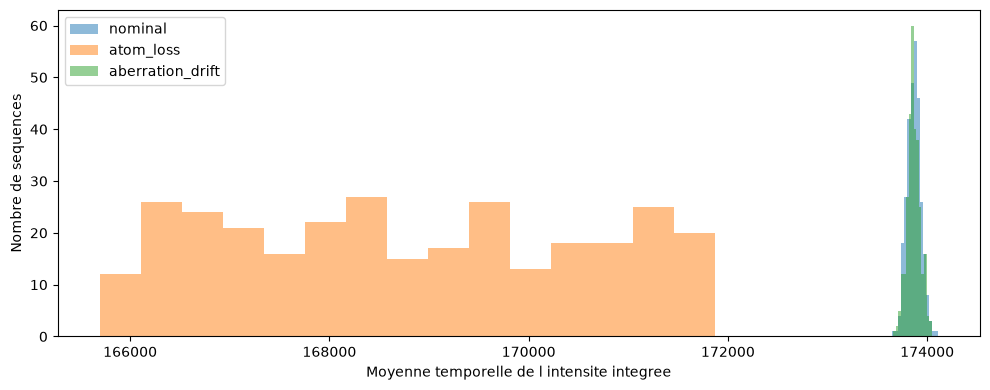

Accuracy triviale (nominal vs atom_loss) : 95.50%


In [6]:
n_seq_per_class = 300
n_frames = 50

t0 = time.time()
all_seqs = {'nominal': [], 'atom_loss': [], 'aberration_drift': []}
all_meta = {'nominal': [], 'atom_loss': [], 'aberration_drift': []}
rng = np.random.default_rng(1)

for _ in range(n_seq_per_class):
    seq, meta = generate_nominal(n_frames, rng=rng)
    all_seqs['nominal'].append(seq); all_meta['nominal'].append(meta)

    t_loss = rng.integers(10, 40)
    seq, meta = generate_atom_loss(n_frames, t_loss=int(t_loss), rng=rng)
    all_seqs['atom_loss'].append(seq); all_meta['atom_loss'].append(meta)

    t_start = rng.integers(5, 25)
    rate = rng.uniform(0.02, 0.15)
    seq, meta = generate_aberration_drift(n_frames, t_start=int(t_start),
                                            rate=float(rate), rng=rng)
    all_seqs['aberration_drift'].append(seq); all_meta['aberration_drift'].append(meta)

print(f'Generation : {time.time()-t0:.1f} s')

features = {}
for cls in all_seqs:
    feats = np.array([seq.sum(axis=(1, 2)).mean() for seq in all_seqs[cls]])
    features[cls] = feats

fig, ax = plt.subplots()
for cls, feats in features.items():
    ax.hist(feats, bins=15, alpha=0.5, label=cls)
ax.set_xlabel('Moyenne temporelle de l intensite integree')
ax.set_ylabel('Nombre de sequences')
ax.legend(); plt.tight_layout(); plt.show()

nom = features['nominal']; loss = features['atom_loss']
threshold = (nom.mean() + loss.mean()) / 2
acc_trivial = (np.mean(nom > threshold) + np.mean(loss < threshold)) / 2
print(f'Accuracy triviale (nominal vs atom_loss) : {acc_trivial:.2%}')

## 5. Sauvegarde

In [12]:
data_root = Path('../data')
for cls in all_seqs:
    cls_dir = data_root / cls
    cls_dir.mkdir(parents=True, exist_ok=True)
    for i, (seq, meta) in enumerate(zip(all_seqs[cls], all_meta[cls])):
        np.savez_compressed(cls_dir / f'seq_{i:03d}.npz',
                           frames=seq, meta=meta)
    print(f'{cls} : {len(all_seqs[cls])} sequences sauvegardees dans {cls_dir}')

test_file = data_root / 'nominal' / 'seq_000.npz'
loaded = np.load(test_file, allow_pickle=True)
print(f'Rechargement OK : frames {loaded["frames"].shape}')

nominal : 300 sequences sauvegardees dans ..\data\nominal
atom_loss : 300 sequences sauvegardees dans ..\data\atom_loss
aberration_drift : 300 sequences sauvegardees dans ..\data\aberration_drift
Rechargement OK : frames (50, 128, 128)


## 6. Conclusion

Voir la sortie de la cellule de séparabilité. Suivant l'accuracy
obtenue, la suite du projet s'oriente vers une évaluation sur la
classe `aberration_drift` (si `atom_loss` est triviale) ou vers une
évaluation conjointe (si les deux classes sont non triviales).


In [ ]:
# =============================================================================
# Cellule de diagnostic : imprime toutes les stats sans graphique
# =============================================================================
import sys, os, time
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
from pathlib import Path
from onn_arquS.config import LAMBDA_399, TrapConfig, ImagingConfig, SimulationConfig
from onn_arquS.physics import sample_positions_gaussian
from onn_arquS.imaging import airy_psf, aberrated_psf, render_intensity, add_scmos_noise

# -------- 1. Détection des données existantes --------
data_root = Path('../data')
classes = ['nominal', 'atom_loss', 'aberration_drift']
existing = {c: sorted((data_root / c).glob('seq_*.npz')) if (data_root / c).exists() else [] for c in classes}
total_files = sum(len(v) for v in existing.values())

print("=" * 70)
print("DIAGNOSTIC DES DONNEES")
print("=" * 70)
print(f"Dossier data/ : {data_root.resolve()}")
print(f"Fichiers trouves : {total_files} (attendu : 90)")
for c in classes:
    print(f"  {c:20s} : {len(existing[c]):3d} fichiers")

# -------- 2. Chargement ou generation --------
USE_EXISTING = total_files >= 90

if USE_EXISTING:
    print("\n[Mode] Chargement depuis disque")
    all_seqs = {c: [] for c in classes}
    all_meta = {c: [] for c in classes}
    for c in classes:
        for f in existing[c][:30]:
            loaded = np.load(f, allow_pickle=True)
            all_seqs[c].append(loaded['frames'])
            all_meta[c].append(loaded['meta'].item())
else:
    print("\n[Mode] Generation en memoire (30 sequences / classe, 50 frames)")
    cfg_trap = TrapConfig(); cfg_img = ImagingConfig(); cfg_sim = SimulationConfig()
    pixel_object_m = cfg_img.pixel_size_m / cfg_img.magnification
    psf_ideal = airy_psf(cfg_sim.grid_size, pixel_object_m, LAMBDA_399, cfg_img.numerical_aperture)

    def _gen_nominal(n_frames, rng):
        frames = []
        for _ in range(n_frames):
            pos = np.array([[
                sample_positions_gaussian(cfg_trap.temperature_k, cfg_trap.omega_hz, 1, rng)[0],
                sample_positions_gaussian(cfg_trap.temperature_k, cfg_trap.omega_hz, 1, rng)[0],
            ]])
            img = render_intensity(pos, psf_ideal, pixel_object_m, 1e4, 10.0)
            frames.append(add_scmos_noise(img, readout_std_map=np.full_like(img, 2.0),
                                          gain_map=np.ones_like(img), rng=rng))
        return np.array(frames), {'class': 'nominal'}

    def _gen_loss(n_frames, t_loss, rng):
        frames = []
        for f in range(n_frames):
            if f >= t_loss:
                img = np.full((cfg_sim.grid_size, cfg_sim.grid_size), 10.0)
            else:
                pos = np.array([[
                    sample_positions_gaussian(cfg_trap.temperature_k, cfg_trap.omega_hz, 1, rng)[0],
                    sample_positions_gaussian(cfg_trap.temperature_k, cfg_trap.omega_hz, 1, rng)[0],
                ]])
                img = render_intensity(pos, psf_ideal, pixel_object_m, 1e4, 10.0)
            frames.append(add_scmos_noise(img, readout_std_map=np.full_like(img, 2.0),
                                          gain_map=np.ones_like(img), rng=rng))
        return np.array(frames), {'class': 'atom_loss', 't_loss': t_loss}

    def _gen_drift(n_frames, t_start, rate, rng):
        frames = []
        for f in range(n_frames):
            coeff = (f - t_start) * rate if f >= t_start else 0.0
            psf_d = aberrated_psf(cfg_sim.grid_size, pixel_object_m, LAMBDA_399,
                                   cfg_img.numerical_aperture, zernike_coeffs={(3, 1): coeff})
            pos = np.array([[
                sample_positions_gaussian(cfg_trap.temperature_k, cfg_trap.omega_hz, 1, rng)[0],
                sample_positions_gaussian(cfg_trap.temperature_k, cfg_trap.omega_hz, 1, rng)[0],
            ]])
            img = render_intensity(pos, psf_d, pixel_object_m, 1e4, 10.0)
            frames.append(add_scmos_noise(img, readout_std_map=np.full_like(img, 2.0),
                                          gain_map=np.ones_like(img), rng=rng))
        return np.array(frames), {'class': 'aberration_drift', 't_start': t_start, 'rate': rate}

    all_seqs = {c: [] for c in classes}
    all_meta = {c: [] for c in classes}
    rng = np.random.default_rng(1)
    t0 = time.time()
    for _ in range(30):
        s, m = _gen_nominal(50, rng); all_seqs['nominal'].append(s); all_meta['nominal'].append(m)
        s, m = _gen_loss(50, int(rng.integers(10, 40)), rng); all_seqs['atom_loss'].append(s); all_meta['atom_loss'].append(m)
        s, m = _gen_drift(50, int(rng.integers(5, 25)), float(rng.uniform(0.02, 0.15)), rng)
        all_seqs['aberration_drift'].append(s); all_meta['aberration_drift'].append(m)
    print(f"Temps de generation : {time.time() - t0:.1f} s")

# -------- 3. Statistiques de forme et de taille --------
print("\n" + "=" * 70)
print("FORMES ET TAILLES")
print("=" * 70)
sample = all_seqs['nominal'][0]
print(f"Shape d'une sequence        : {sample.shape}  (frames, H, W)")
print(f"dtype                       : {sample.dtype}")
n_files = total_files if USE_EXISTING else 90
file_size_mb = (data_root.rglob('*.npz') and
                sum(f.stat().st_size for f in data_root.rglob('*.npz'))) / 1e6 if USE_EXISTING else 0
print(f"Fichiers sur disque         : {n_files}")
print(f"Taille totale sur disque    : {file_size_mb:.1f} MB")

# -------- 4. Metadonnees --------
print("\n" + "=" * 70)
print("METADONNEES (une par classe)")
print("=" * 70)
for c in classes:
    print(f"{c:20s} : {all_meta[c][0]}")

# -------- 5. Statistiques par classe --------
print("\n" + "=" * 70)
print("STATISTIQUES PAR CLASSE")
print("=" * 70)
for c in classes:
    seqs = np.array(all_seqs[c])  # (n_seq, n_frames, H, W)
    total_flux = seqs.sum(axis=(2, 3))  # (n_seq, n_frames)
    print(f"\n{c} :")
    print(f"  Flux total (par frame)    : mean={total_flux.mean():.1f}, "
          f"std={total_flux.std():.1f}, "
          f"min={total_flux.min():.1f}, max={total_flux.max():.1f}")
    print(f"  Var. temporelle du flux   : mean={total_flux.std(axis=1).mean():.1f}")
    # Variance spatiale moyenne (proxy de largeur de PSF)
    spatial_var = np.array([[np.var(f) for f in s] for s in seqs])
    print(f"  Var. spatiale (par frame) : mean={spatial_var.mean():.1f}")

# -------- 6. Tests de separabilite triviale --------
print("\n" + "=" * 70)
print("TESTS DE SEPARABILITE (classifieur a seuil median)")
print("=" * 70)

def _threshold_acc(f1, f2):
    th = (np.mean(f1) + np.mean(f2)) / 2
    return max(np.mean(f1 > th) * 0.5 + np.mean(f2 <= th) * 0.5,
               np.mean(f1 <= th) * 0.5 + np.mean(f2 > th) * 0.5)

# Features candidates
feats = {}
for c in classes:
    seqs = np.array(all_seqs[c])
    total_flux = seqs.sum(axis=(2, 3))            # (n_seq, n_frames)
    feats[c] = {
        'flux_moyen':        total_flux.mean(axis=1),
        'flux_std_temp':     total_flux.std(axis=1),
        'flux_diff_moitie':  total_flux[:, 25:].mean(axis=1) - total_flux[:, :25].mean(axis=1),
        'var_spatiale_moy':  seqs.var(axis=(2, 3)).mean(axis=1),
    }

for feature_name in ['flux_moyen', 'flux_std_temp', 'flux_diff_moitie', 'var_spatiale_moy']:
    print(f"\n  Feature : {feature_name}")
    for c1, c2 in [('nominal', 'atom_loss'), ('nominal', 'aberration_drift'),
                   ('atom_loss', 'aberration_drift')]:
        acc = _threshold_acc(feats[c1][feature_name], feats[c2][feature_name])
        print(f"    {c1:18s} vs {c2:18s} : accuracy = {acc:.2%}")

# -------- 7. Verdict --------
print("\n" + "=" * 70)
print("VERDICT")
print("=" * 70)
best_acc_loss = _threshold_acc(feats['nominal']['flux_moyen'], feats['atom_loss']['flux_moyen'])
best_acc_drift = _threshold_acc(feats['nominal']['flux_moyen'], feats['aberration_drift']['flux_moyen'])
print(f"Meilleure accuracy triviale (nominal vs atom_loss)     : {best_acc_loss:.2%}")
print(f"Meilleure accuracy triviale (nominal vs drift)         : {best_acc_drift:.2%}")
if max(best_acc_loss, best_acc_drift) > 0.90:
    print("-> Au moins une classe est triviale : le reseau photonique")
    print("   devra etre evalue en priorite sur la classe NON triviale.")
else:
    print("-> Les deux classes resistent au classifieur trivial :")
    print("   le reseau photonique a une reelle valeur ajoutee.")